# 4. Segmenting borrowers: composition versus environment

Banks manage mortgage books by **segments** of similar borrowers, not loan by loan. This notebook builds segments with two multivariate tools, principal components and k-means, and uses them to split the 2006–2017 default gap into two parts:

- **composition:** 2006 had more risky borrowers;
- **environment:** the *same kind* of borrower defaulted more in 2006.

In [1]:
import sys
sys.path.insert(0, "../src")
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

from credit_risk.data import load_loans
from credit_risk.survival import cif_at

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREY = "#1a73e8", "#d93025", "#80868b"

loans = load_loans((2006, 2017)).dropna(subset=["fico", "ltv", "cltv", "dti", "rate"]).reset_index(drop=True)
features = pd.DataFrame({
    "fico": loans["fico"],
    "ltv": loans["ltv"],
    "cltv": loans["cltv"],
    "dti": loans["dti"],
    "rate_premium": loans["rate"] - loans.groupby("vintage")["rate"].transform("median"),
    "log_balance": np.log(loans["upb"]),
})
Z = StandardScaler().fit_transform(features)      # same scale for every variable
features.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
fico,734.579,53.599,300.0,844.0
ltv,72.662,17.293,6.0,102.0
cltv,74.123,17.92,6.0,160.0
dti,35.84,10.854,1.0,65.0
rate_premium,0.018,0.415,-2.875,3.415
log_balance,12.08,0.576,9.21,13.816


## Principal components: what varies together?

In [2]:
pca = PCA().fit(Z)
explained = pd.Series(pca.explained_variance_ratio_, index=[f"PC{i+1}" for i in range(Z.shape[1])])
loadings = pd.DataFrame(pca.components_[:3].T, index=features.columns, columns=["PC1", "PC2", "PC3"])
display(explained.to_frame("share of variance").T)
loadings

,PC1,PC2,PC3,PC4,PC5,PC6
share of variance,0.356,0.213,0.177,0.127,0.121,0.007


,PC1,PC2,PC3
fico,-0.142,0.617,-0.228
ltv,0.651,0.112,-0.193
cltv,0.652,0.110,-0.190
dti,0.183,-0.178,0.782
rate_premium,0.223,-0.577,-0.151
log_balance,0.218,0.479,0.491


The first component is essentially **leverage**: loan-to-value and combined loan-to-value move together. The next ones separate **credit quality and pricing** (credit score against the rate premium) and **affordability** (debt-to-income, loan size). Three components summarise most of the variation; the six variables are far from independent, which is why a handful of segments can describe the book.

## k-means segments

Choosing the number of segments with the silhouette score (computed on a random subsample of 10,000 loans; higher is better):

In [3]:
rng = np.random.default_rng(2026)
sample = rng.choice(len(Z), 10_000, replace=False)
sil = {k: silhouette_score(Z[sample], KMeans(k, n_init=10, random_state=1).fit_predict(Z[sample])) for k in range(3, 8)}
pd.Series(sil, name="silhouette").to_frame().T

,3,4,5,6,7
silhouette,0.178,0.16,0.156,0.152,0.149


In [4]:
K = max(sil, key=sil.get)
km = KMeans(K, n_init=20, random_state=1).fit(Z)
profile = features.assign(segment=km.labels_).groupby("segment").mean()

# Name each segment from its own profile (cluster numbers are arbitrary)
names = {profile["fico"].idxmin(): "lower score, higher DTI",
         profile["ltv"].idxmin(): "large down payment (low LTV)"}
names.update({s: "prime, high LTV" for s in profile.index if s not in names})
loans["segment"] = pd.Series(km.labels_).map(names).values
profile.index = profile.index.map(names)
profile["share of loans"] = loans["segment"].value_counts(normalize=True)
profile

,fico,ltv,cltv,dti,rate_premium,log_balance,share of loans
segment,,,,,,,
"lower score, higher DTI",690.557,79.948,81.765,39.049,0.298,11.928,0.347
"prime, high LTV",763.225,79.711,81.264,34.618,-0.128,12.323,0.444
large down payment (low LTV),746.754,45.561,46.234,33.110,-0.133,11.815,0.209


The silhouette scores are low for every k (about 0.15–0.18): mortgage borrowers do not form well-separated natural groups, they vary continuously. The segments are therefore a **useful partition** of the book, the way a risk team uses them, not a discovery of hidden types. The three-segment solution has a clear reading: a lower-score, higher-DTI segment priced above the market; a prime segment with high loan-to-value; and borrowers with a large down payment.

How the two vintages were distributed across segments, and how each segment performed:

In [5]:
mix = pd.crosstab(loans["segment"], loans["vintage"], normalize="columns")
mix.columns = [f"share of {c} book" for c in mix.columns]

cif = cif_at(loans, months=(60,), by=["vintage", "segment"])["60 months"].unstack("vintage")
cif.columns = [f"default within 60 m, {c}" for c in cif.columns]
seg = mix.join(cif)
seg["ratio 2006 / 2017"] = seg.iloc[:, 2] / seg.iloc[:, 3]
seg = seg.join(profile[["fico", "ltv", "dti"]].round(0))
seg

,share of 2006 book,share of 2017 book,"default within 60 m, 2006","default within 60 m, 2017",ratio 2006 / 2017,fico,ltv,dti
segment,,,,,,,,
large down payment (low LTV),0.244,0.173,0.042,0.009,4.800,747.0,46.0,33.0
"lower score, higher DTI",0.415,0.278,0.179,0.040,4.444,691.0,80.0,39.0
"prime, high LTV",0.341,0.549,0.072,0.010,7.285,763.0,80.0,35.0


## Splitting the gap

A simple counterfactual answers the question of the project. **If the 2006 book had had the 2017 mix of segments**, its 60-month default rate would have been the 2006 segment rates weighted by the 2017 mix:

In [6]:
w06, w17 = seg.iloc[:, 0], seg.iloc[:, 1]
d06, d17 = seg.iloc[:, 2], seg.iloc[:, 3]
actual_06, actual_17 = (w06 * d06).sum(), (w17 * d17).sum()
counterfactual = (w17 * d06).sum()          # 2006 environment, 2017 borrowers
gap = actual_06 - actual_17
decomp = pd.Series({
    "2006 actual (segment-weighted)": actual_06,
    "2006 environment with 2017 borrowers": counterfactual,
    "2017 actual (segment-weighted)": actual_17,
    "share of the gap due to composition": (actual_06 - counterfactual) / gap,
    "share of the gap due to environment": (counterfactual - actual_17) / gap,
})
decomp

2006 actual (segment-weighted)          0.109
2006 environment with 2017 borrowers    0.097
2017 actual (segment-weighted)          0.018
share of the gap due to composition     0.137
share of the gap due to environment     0.863
dtype: float64

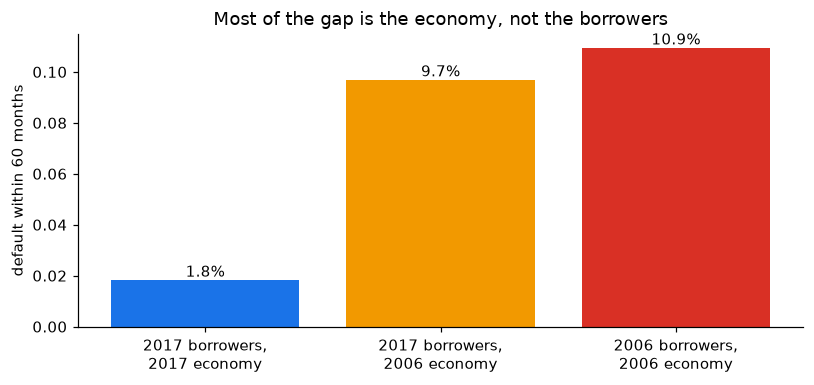

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
bars = [actual_17, counterfactual, actual_06]
labels = ["2017 borrowers,\n2017 economy", "2017 borrowers,\n2006 economy", "2006 borrowers,\n2006 economy"]
ax.bar(labels, bars, color=[BLUE, "#f29900", RED])
for i, b in enumerate(bars):
    ax.text(i, b, f"{b:.1%}", ha="center", va="bottom")
ax.set_ylabel("default within 60 months")
ax.set_title("Most of the gap is the economy, not the borrowers")
fig.tight_layout()
fig.savefig("../figures/composition_vs_environment.png", bbox_inches="tight")
plt.show()

Changing the borrowers to the safer 2017 mix lowers the 2006 default rate only a little; almost all of the gap remains. **The 2006 vintage did not fail mainly because it lent to worse borrowers, but because ordinary borrowers met a collapse in house prices.** The Cox model of notebook 3 reached the same conclusion with a different tool (a hazard ratio of about 4.6 for the vintage after adjusting for the borrower), which is the kind of agreement a validator looks for.

*Limits:* segments use continuous variables only (purpose, occupancy and number of borrowers are left to the Cox model), and k-means assumes roughly spherical clusters in the standardised space. The decomposition is descriptive: "environment" is everything that differs between the vintages beyond these six variables, including underwriting practices the data do not record.

In [8]:
seg.to_csv("../results/segments.csv")
decomp.to_csv("../results/composition_vs_environment.csv")
loadings.to_csv("../results/pca_loadings.csv")